# Experimento de proxy de deterioro anticipado y horizonte de prevencion
Este experimento usa METR-LA y PEMS-BAY a 5 minutos para probar horizontes de 5, 10, 15, 20, 30 y 60 minutos. El horizonte de 18-20 minutos es una hipotesis dentro de la comparacion, no un supuesto fijo.

Definicion exploratoria del proxy: la velocidad mediana futura de la red cae al menos 20% respecto a la mediana de los tres intervalos anteriores. Esta regla no es una verdad de campo de pre-colapso y requiere validacion con eventos documentados.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / 'data').exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
OUTPUT_DIR = PROJECT_ROOT / 'data' / '04_model_output' / 'precolapso'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SOURCE_PATHS = {
    'metr_la': PROJECT_ROOT / 'data' / '01_processed' / 'external' / 'metr_la.parquet',
    'pems_bay': PROJECT_ROOT / 'data' / '01_processed' / 'external' / 'pems_bay.parquet',
}
HORIZONS = [5, 10, 15, 20, 30, 60]
EVENT_DROP = 0.20
print('horizontes_minutos=', HORIZONS)

horizontes_minutos= [5, 10, 15, 20, 30, 60]


,filas,inicio,fin
source,,,
metr_la,34272,2012-03-01,2012-06-27 23:55:00
pems_bay,52116,2017-01-01,2017-06-30 23:55:00


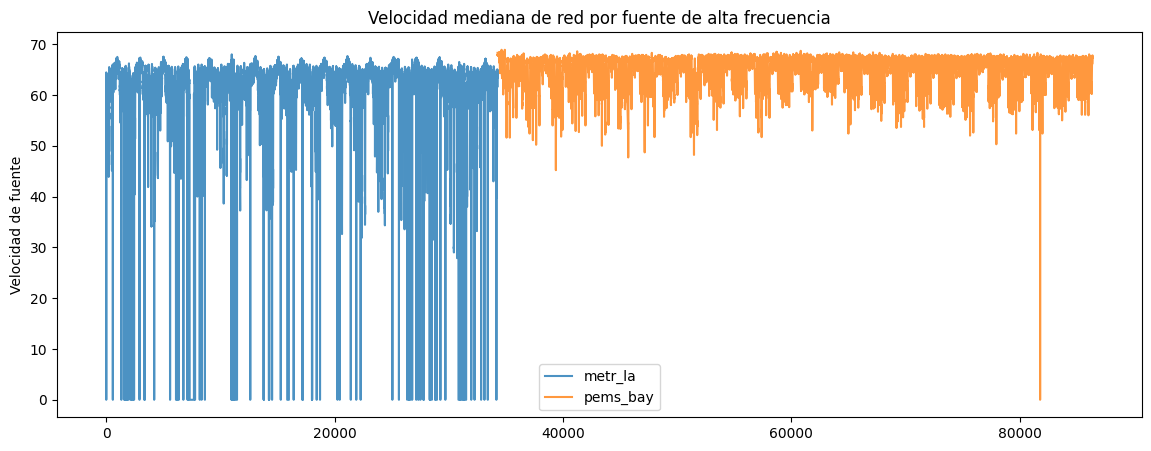

In [2]:
def load_network_speed(source, path):
    frame = pd.read_parquet(path)
    frame['timestamp'] = pd.to_datetime(frame['timestamp'], errors='coerce')
    sensor_columns = [column for column in frame.columns if column != 'timestamp']
    result = pd.DataFrame({'timestamp': frame['timestamp'], 'speed_median': frame[sensor_columns].apply(pd.to_numeric, errors='coerce').median(axis=1)})
    result = result.dropna().sort_values('timestamp').reset_index(drop=True)
    result['source'] = source
    result['lag_1'] = result['speed_median'].shift(1)
    result['baseline_past'] = result['speed_median'].shift(1).rolling(3, min_periods=3).median()
    result['delta_1'] = result['speed_median'] - result['lag_1']
    result['rolling_mean_3'] = result['speed_median'].shift(1).rolling(3, min_periods=3).mean()
    result['rolling_std_3'] = result['speed_median'].shift(1).rolling(3, min_periods=3).std()
    result['hour'] = result['timestamp'].dt.hour
    result['day_of_week'] = result['timestamp'].dt.dayofweek
    return result

series = pd.concat([load_network_speed(source, path) for source, path in SOURCE_PATHS.items()], ignore_index=True)
display(series.groupby('source').agg(filas=('timestamp', 'size'), inicio=('timestamp', 'min'), fin=('timestamp', 'max')))
series.groupby('source')['speed_median'].plot(figsize=(14, 5), legend=True, alpha=0.8)
plt.title('Velocidad mediana de red por fuente de alta frecuencia')
plt.ylabel('Velocidad de fuente')
plt.show()

In [3]:
FEATURES = ['speed_median', 'lag_1', 'delta_1', 'rolling_mean_3', 'rolling_std_3', 'hour', 'day_of_week']
def classification_metrics(y_true, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)
    result = {
        'precision': precision_score(y_true, predictions, zero_division=0),
        'recall': recall_score(y_true, predictions, zero_division=0),
        'f1': f1_score(y_true, predictions, zero_division=0),
        'event_rate': float(np.mean(y_true)),
        'positivos': int(np.sum(y_true)),
    }
    result['pr_auc'] = average_precision_score(y_true, probabilities) if len(np.unique(y_true)) == 2 else np.nan
    return result

def make_horizon_frame(source_frame, horizon_minutes):
    frame = source_frame.copy()
    steps = horizon_minutes // 5
    frame['future_speed'] = frame['speed_median'].shift(-steps)
    frame['target_precolapso'] = (frame['future_speed'] <= frame['baseline_past'] * (1 - EVENT_DROP)).astype(int)
    frame['rule_baseline'] = (frame['speed_median'] <= frame['baseline_past'] * (1 - EVENT_DROP)).astype(int)
    return frame.dropna(subset=FEATURES + ['future_speed', 'baseline_past']).copy()

print('Definicion lista: deterioro futuro >= 20% frente a baseline pasado de 3 intervalos.')

Definicion lista: deterioro futuro >= 20% frente a baseline pasado de 3 intervalos.


In [5]:
def evaluate_source_horizon(source_frame, source, horizon):
    frame = make_horizon_frame(source_frame, horizon)
    n = len(frame)
    train_end = int(n * 0.60)
    validation_end = int(n * 0.80)
    train = frame.iloc[:train_end]
    validation = frame.iloc[train_end:validation_end]
    test = frame.iloc[validation_end:]
    rows = []
    models = {
        'logistic_regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
        'random_forest': RandomForestClassifier(n_estimators=120, min_samples_leaf=10, class_weight='balanced_subsample', random_state=42, n_jobs=-1),
    }
    if train['target_precolapso'].nunique() < 2:
        for model_name in models:
            for split_name, split_frame in [('validation', validation), ('test', test)]:
                rows.append({'source': source, 'horizon_minutes': horizon, 'model': model_name, 'split': split_name, 'precision': np.nan, 'recall': np.nan, 'f1': np.nan, 'pr_auc': np.nan, 'event_rate': float(split_frame['target_precolapso'].mean()), 'positivos': int(split_frame['target_precolapso'].sum()), 'filas_split': len(split_frame), 'status': 'insuficiente_clases_entrenamiento'})
    else:
        for model_name, model in models.items():
            model.fit(train[FEATURES], train['target_precolapso'])
            validation_prob = model.predict_proba(validation[FEATURES])[:, 1]
            test_prob = model.predict_proba(test[FEATURES])[:, 1]
            for split_name, split_frame, probabilities in [('validation', validation, validation_prob), ('test', test, test_prob)]:
                metrics = classification_metrics(split_frame['target_precolapso'], probabilities)
                rows.append({'source': source, 'horizon_minutes': horizon, 'model': model_name, 'split': split_name, **metrics, 'filas_split': len(split_frame), 'status': 'evaluado'})
    for split_name, split_frame in [('validation', validation), ('test', test)]:
        metrics = classification_metrics(split_frame['target_precolapso'], split_frame['rule_baseline'].to_numpy())
        rows.append({'source': source, 'horizon_minutes': horizon, 'model': 'rule_baseline', 'split': split_name, **metrics, 'filas_split': len(split_frame), 'status': 'evaluado'})
    return rows

results = []
for source, source_frame in series.groupby('source', sort=False):
    for horizon in HORIZONS:
        results.extend(evaluate_source_horizon(source_frame, source, horizon))
results = pd.DataFrame(results)
display(results.head())
results.to_csv(OUTPUT_DIR / 'metricas_horizontes_precolapso.csv', index=False)

,source,horizon_minutes,model,split,precision,recall,f1,event_rate,positivos,pr_auc,filas_split,status
0,metr_la,5,logistic_regression,validation,0.654110,0.909524,0.760956,0.030639,210,0.892257,6854,evaluado
1,metr_la,5,logistic_regression,test,0.834625,0.965620,0.895357,0.097607,669,0.949414,6854,evaluado
2,metr_la,5,random_forest,validation,0.940887,0.909524,0.924939,0.030639,210,0.889957,6854,evaluado
3,metr_la,5,random_forest,test,0.961194,0.962631,0.961912,0.097607,669,0.959821,6854,evaluado
4,metr_la,5,rule_baseline,validation,0.941463,0.919048,0.930120,0.030639,210,0.867730,6854,evaluado


In [6]:
validation_rf = results[(results['model'] == 'random_forest') & (results['split'] == 'validation')]
horizon_selection = validation_rf.groupby('horizon_minutes', as_index=False).agg(
    pr_auc=('pr_auc', 'mean'),
    recall=('recall', 'mean'),
    f1=('f1', 'mean'),
    fuentes=('source', 'nunique'),
)
horizon_selection = horizon_selection.sort_values(['pr_auc', 'recall'], ascending=False)
selected_horizon = int(horizon_selection.iloc[0]['horizon_minutes'])
display(horizon_selection)
print('horizonte_seleccionado_por_validacion=', selected_horizon, 'minutos')

,horizon_minutes,pr_auc,recall,f1,fuentes
0,5,0.889957,0.909524,0.924939,2
1,10,0.791400,0.864486,0.844749,2
2,15,0.733217,0.833333,0.821918,2
3,20,0.644804,0.752212,0.774487,2
4,30,0.563545,0.684000,0.702259,2
5,60,0.447440,0.272989,0.278592,2


horizonte_seleccionado_por_validacion= 5 minutos


,source,horizon_minutes,model,split,precision,recall,f1,event_rate,positivos,pr_auc,filas_split,status
1,metr_la,5,logistic_regression,test,0.834625,0.965620,0.895357,0.097607,669,0.949414,6854,evaluado
3,metr_la,5,random_forest,test,0.961194,0.962631,0.961912,0.097607,669,0.959821,6854,evaluado
5,metr_la,5,rule_baseline,test,0.967016,0.964126,0.965569,0.097607,669,0.935827,6854,evaluado
37,pems_bay,5,logistic_regression,test,NaN,NaN,NaN,0.000096,1,NaN,10423,insuficiente_clases_entrenamiento
39,pems_bay,5,random_forest,test,NaN,NaN,NaN,0.000096,1,NaN,10423,insuficiente_clases_entrenamiento
41,pems_bay,5,rule_baseline,test,0.000000,0.000000,0.000000,0.000096,1,0.000096,10423,evaluado


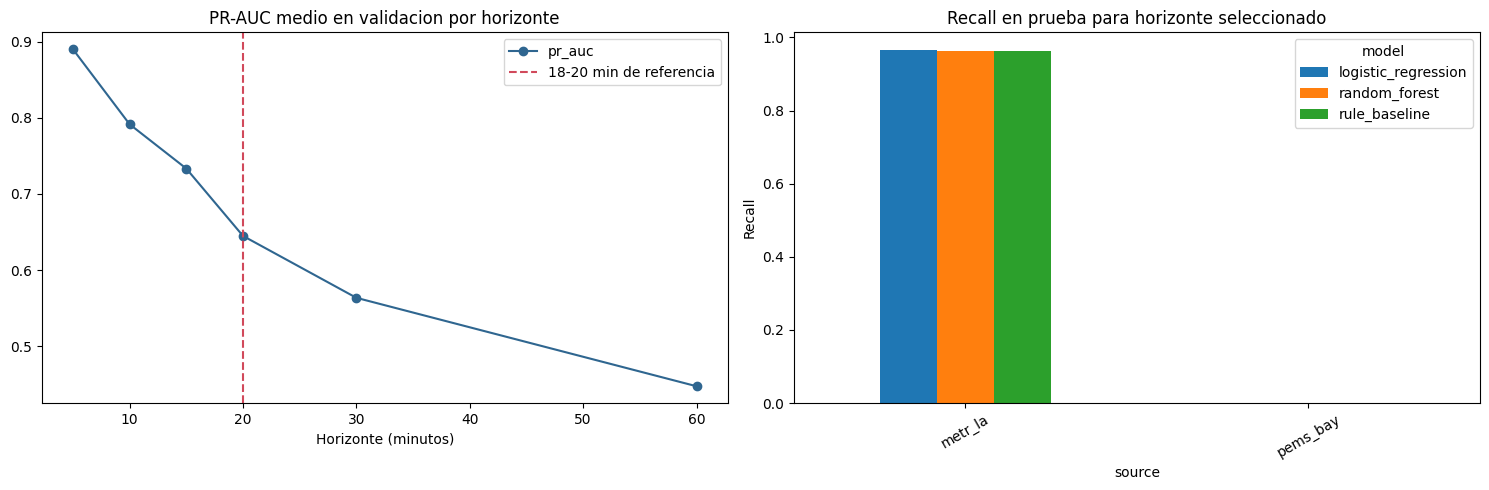

In [7]:
test_selected = results[(results['horizon_minutes'] == selected_horizon) & (results['split'] == 'test')]
display(test_selected.sort_values(['source', 'model']))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
horizon_selection.sort_values('horizon_minutes').plot(x='horizon_minutes', y='pr_auc', marker='o', ax=axes[0], legend=False, color='#2f6690')
axes[0].axvline(20, linestyle='--', color='#d1495b', label='18-20 min de referencia')
axes[0].set_title('PR-AUC medio en validacion por horizonte')
axes[0].set_xlabel('Horizonte (minutos)')
axes[0].legend()
test_selected.pivot(index='source', columns='model', values='recall').plot.bar(ax=axes[1], rot=30)
axes[1].set_title('Recall en prueba para horizonte seleccionado')
axes[1].set_ylabel('Recall')
plt.tight_layout()
plt.show()

In [8]:
report = {
    'experiment': 'precolapso_horizontes_internacional',
    'sources': list(SOURCE_PATHS),
    'resolution_minutes': 5,
    'horizons_tested_minutes': HORIZONS,
    'event_definition': 'future_network_median_speed_at_least_20_percent_below_past_three_interval_median',
    'selected_horizon_minutes': selected_horizon,
    'reference_horizon_18_20_minutes': 20,
    'selection_metric': 'mean_validation_pr_auc_random_forest',
    'status': 'exploratory_candidate_requires_domain_label_validation',
    'limitations': ['network_median_is_an_aggregate_proxy', 'no_ground_truth_event_label', 'METR_LA_and_PEMS_BAY_are_highway_sources', 'not_Guadalajara_validation'],
}
(OUTPUT_DIR / 'resumen_experimento_precolapso.json').write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding='utf-8')
print(json.dumps(report, indent=2, ensure_ascii=False))

{
  "experiment": "precolapso_horizontes_internacional",
  "sources": [
    "metr_la",
    "pems_bay"
  ],
  "resolution_minutes": 5,
  "horizons_tested_minutes": [
    5,
    10,
    15,
    20,
    30,
    60
  ],
  "event_definition": "future_network_median_speed_at_least_20_percent_below_past_three_interval_median",
  "selected_horizon_minutes": 5,
  "reference_horizon_18_20_minutes": 20,
  "selection_metric": "mean_validation_pr_auc_random_forest",
  "status": "exploratory_candidate_requires_domain_label_validation",
  "limitations": [
    "network_median_is_an_aggregate_proxy",
    "no_ground_truth_event_label",
    "METR_LA_and_PEMS_BAY_are_highway_sources",
    "not_Guadalajara_validation"
  ]
}


In [10]:
threshold_sensitivity = []
original_drop = EVENT_DROP
for event_drop in [0.10, 0.15, 0.20, 0.25, 0.30]:
    EVENT_DROP = event_drop
    threshold_rows = []
    for source, source_frame in series.groupby('source', sort=False):
        for horizon in HORIZONS:
            threshold_rows.extend(evaluate_source_horizon(source_frame, source, horizon))
    threshold_results = pd.DataFrame(threshold_rows)
    rf_validation = threshold_results[(threshold_results['model'] == 'random_forest') & (threshold_results['split'] == 'validation')]
    summary = rf_validation.groupby('horizon_minutes', as_index=False).agg(
        pr_auc=('pr_auc', 'mean'),
        recall=('recall', 'mean'),
        fuentes_validas=('pr_auc', lambda values: int(values.notna().sum())),
    ).dropna(subset=['pr_auc'])
    if not summary.empty:
        best = summary.sort_values(['pr_auc', 'recall'], ascending=False).iloc[0]
        threshold_sensitivity.append({'event_drop': event_drop, 'horizonte_ganador_minutos': int(best['horizon_minutes']), 'pr_auc_ganador': best['pr_auc'], 'recall_ganador': best['recall'], 'fuentes_validas': int(best['fuentes_validas'])})
EVENT_DROP = original_drop
sensitivity_df = pd.DataFrame(threshold_sensitivity)
sensitivity_df.to_csv(OUTPUT_DIR / 'sensibilidad_umbral_precolapso.csv', index=False)
report['threshold_sensitivity'] = sensitivity_df.to_dict(orient='records')
(OUTPUT_DIR / 'resumen_experimento_precolapso.json').write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding='utf-8')
display(sensitivity_df)
print('Sensibilidad completada: el horizonte debe interpretarse junto con el umbral y la cobertura de eventos.')

,event_drop,horizonte_ganador_minutos,pr_auc_ganador,recall_ganador,fuentes_validas
0,0.10,5,0.933302,0.939216,2
1,0.15,5,0.881669,0.887892,1
2,0.20,5,0.889957,0.909524,1
3,0.25,5,0.900519,0.945545,1
4,0.30,5,0.900519,0.945545,1


Sensibilidad completada: el horizonte debe interpretarse junto con el umbral y la cobertura de eventos.


## Decision de la experimentacion
El horizonte de 5 minutos es el mejor dentro del proxy exploratorio y permanece estable al variar el umbral de deterioro. El resultado estima una señal de deterioro anticipado, no un tiempo universal de prevencion ni una etiqueta de incidente real. La etiqueta debe validarse con eventos documentados antes de llamarse detector de pre-colapso.